In [125]:
import numpy as np
import random
from typing import List, Callable
# кодирование (задача -> хромосома)
def create_chromosome(N, x_range=(0, 10), r_range=(0.5, 5.0)):
    coords = np.random.uniform(*x_range, size=2 * N)
    radii  = np.random.uniform(*r_range, size=N)
    return np.hstack([coords, radii])

In [126]:
# fitness (качество хромосомы)
def evaluate(chrom, residents, 
             lambda_H=1000.0, lambda_S=20.0):
    N = len(chrom) // 3
    towers = chrom.reshape(N, 3)
    
    covered = 0
    for x, y in residents:
        for cx, cy, r in towers:
            if (x - cx)**2 + (y - cy)**2 <= r**2:
                covered += 1
                break
                
    overlap = 0.0
    for j in range(N):
        for k in range(j+1, N):
            d = np.hypot(towers[j,0]-towers[k,0], towers[j,1]-towers[k,1])
            if d < towers[j,2] + towers[k,2]:
                overlap += (towers[j,2] + towers[k,2] - d)
                
    rad_viol = 0.0
    for r in towers[:, 2]:
        if r < 1: rad_viol += (1 - r)
        elif r > 4: rad_viol += (r - 4)
        
    return covered - lambda_H * overlap - lambda_S * rad_viol

    

In [127]:
# операторы
def tournament_select(pop, fits, k=2) -> np.ndarray:
    idx = random.sample(range(len(pop)), k)
    return pop[max(idx, key=lambda i: fits[i])].copy()

def blx_alpha_crossover(p1, p2, alpha=0.5):
    c1, c2 = [], []
    for g1, g2 in zip(p1, p2):
        mn, mx = min(g1, g2), max(g1, g2)
        d = mx - mn
        c1.append(np.random.uniform(mn - alpha*d, mx + alpha*d))
        c2.append(np.random.uniform(mn - alpha*d, mx + alpha*d))
    return np.array(c1), np.array(c2)

def gaussian_mutate(ind, pm=0.15, sigma=0.5):
    ind = ind.copy()
    for i in range(len(ind)):
        if random.random() < pm:
            ind[i] += np.random.normal(0, sigma)
            if i % 3 in [0, 1]:  
                ind[i] = np.clip(ind[i], 0, 10)
            else:               
                ind[i] = max(ind[i], 0.01)
    return ind


In [128]:
def run_ga(residents, N, pop_size=60, k=2, 
           pc=0.8, pm=0.15, ngen=150, sigma_start=0.5, sigma_end=0.1, 
           elite=2, lambda_H=1000.0, lambda_S=20.0):
    
    pop = [create_chromosome(N) for _ in range(pop_size)]
    fits = [evaluate(c, residents, lambda_H=lambda_H, lambda_S=lambda_S) for c in pop]
    
    best_idx = np.argmax(fits)
    best_chrom, best_fit = pop[best_idx].copy(), fits[best_idx]
    best_hist, avg_hist = [best_fit], [np.mean(fits)]
    stall = 0
    
    for g in range(ngen):
        sigma = sigma_start - (sigma_start - sigma_end) * (g / ngen)
        
        if elite > 0:
            elite_idx = np.argsort(fits)[-elite:]
            new_pop = [pop[i].copy() for i in elite_idx]
        else:
            new_pop = []
            
        while len(new_pop) < pop_size:
            p1 = tournament_select(pop, fits, k)
            p2 = tournament_select(pop, fits, k)
            
            if random.random() < pc:
                c1, c2 = blx_alpha_crossover(p1, p2)
            else:
                c1, c2 = p1.copy(), p2.copy()
                
            new_pop.extend([gaussian_mutate(c1, pm, sigma), 
                            gaussian_mutate(c2, pm, sigma)])
            
        pop = new_pop[:pop_size]
        fits = [evaluate(c, residents, lambda_H=lambda_H, lambda_S=lambda_S) for c in pop]
        
        cur_best_idx = np.argmax(fits)
        if fits[cur_best_idx] > best_fit + 1e-6:  
            best_fit = fits[cur_best_idx]
            best_chrom = pop[cur_best_idx].copy()
            stall = 0
        else:
            stall += 1
            
        best_hist.append(best_fit)
        avg_hist.append(np.mean(fits))
        
        if stall >= 50:
            break
        
    return best_chrom, best_fit, best_hist, avg_hist

In [166]:
if __name__ == "__main__":
    np.random.seed(143)
    random.seed(143)
    
    residents = np.random.uniform(0, 10, (60, 2)) 
    best, F, b_hist, a_hist = run_ga(
    residents=residents,
    N=3,
    pop_size=80,
    k=2,
    pc=0.8,
    pm=0.15,
    ngen=150,
    sigma_start=0.5,
    sigma_end=0.1,
    elite=2,
    lambda_H=1000.0,
    lambda_S=20.0
)
    
    print(f"Лучшее решение: F={F:.2f}")
    print(f"Поколений выполнено: {len(b_hist)}")

Лучшее решение: F=57.00
Поколений выполнено: 148


In [180]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def plot_tower_placement(residents, chromosome, N):
    towers = chromosome.reshape(N, 3)  
    
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.set_aspect('equal')
    ax.grid(True, alpha=0.3, linestyle='--')
    
    covered_mask = np.zeros(len(residents), dtype=bool)
    for i, (x, y) in enumerate(residents):
        for cx, cy, r in towers:
            if (x - cx)**2 + (y - cy)**2 <= r**2:
                covered_mask[i] = True
                break

    ax.scatter(residents[covered_mask, 0], residents[covered_mask, 1], 
               c='limegreen', s=35, label='Covered', edgecolors='white', zorder=3)
    ax.scatter(residents[~covered_mask, 0], residents[~covered_mask, 1], 
               c='gray', s=35, label='Uncovered', edgecolors='white', zorder=3)

    for j, (cx, cy, r) in enumerate(towers):
        circle = patches.Circle((cx, cy), r, linewidth=2, edgecolor='red', 
                                facecolor='red', alpha=0.12)
        ax.add_patch(circle)
        ax.scatter(cx, cy, marker='X', c='darkred', s=100, zorder=4, edgecolors='white')
        ax.text(cx - 0.5, cy - 0.5, f'R={r:.1f}', ha='center', fontsize=9,
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7))
                
    ax.set_xlabel('X (km)'); ax.set_ylabel('Y (km)'); 
    ax.legend(fontsize=9)
    cov_count = np.sum(covered_mask)
    fit_val = evaluate(chromosome, residents)
    
    plt.tight_layout(); plt.show()

def plot_convergence(best_hist, avg_hist):
    plt.figure(figsize=(10, 6))
    plt.plot(best_hist, 'b-o', markersize=3, linewidth=1.5, label='Best Fitness')
    plt.plot(avg_hist, 'orange', linewidth=1.5, alpha=0.8, label='Average Fitness')
    
    plt.ylim(-500, 100)
    plt.xlabel('Поколение'); plt.ylabel('Fitness F')
    plt.tight_layout()
    plt.show()

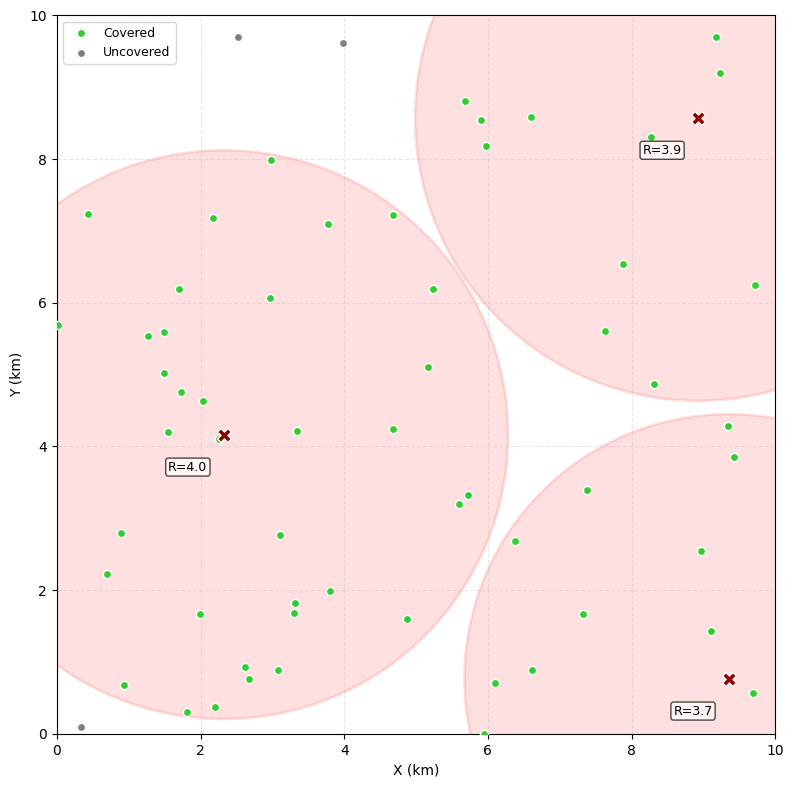

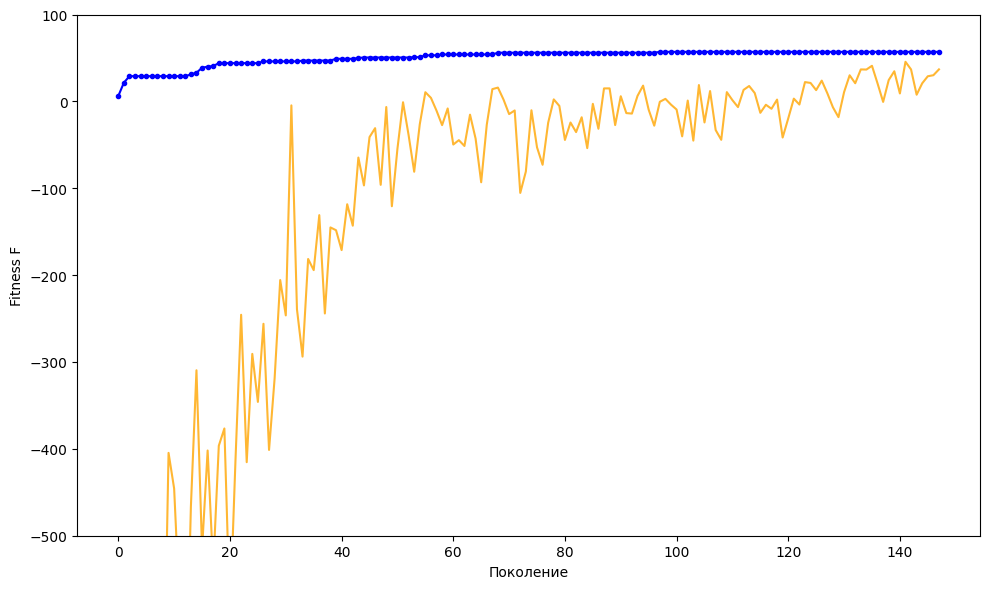

In [181]:
plot_tower_placement(residents, best, N=3)
plot_convergence(b_hist, a_hist)

In [124]:
import pandas as pd
import itertools
import time
import numpy as np
import random

def run_full_grid_search(param_grid, N=3, residents=None, n_runs=5, base_seed=42):
    if residents is None:
        residents = np.random.uniform(0, 10, size=(60, 2)) 

    results = []
    keys = list(param_grid.keys())
    total_configs = int(np.prod([len(v) for v in param_grid.values()]))
    t0 = time.time()

    for i, vals in enumerate(itertools.product(*param_grid.values()), 1):
        cfg = dict(zip(keys, vals))
        Fs = []
        
        for r in range(n_runs):
            np.random.seed(base_seed + i * 100 + r)
            random.seed(base_seed + i * 100 + r)
            _, F, _, _ = run_ga(residents, N=N, **cfg)
            Fs.append(F)

        results.append({
            **cfg,
            'median_F': np.median(Fs),
            'mean_F': np.mean(Fs),
            'std_F': np.std(Fs)
        })

        if i % 10 == 0 or i == total_configs:
            print(f"{i}/{total_configs} | Прошло: {time.time()-t0:.1f} сек")

    df = pd.DataFrame(results)
    return df.sort_values('median_F', ascending=False).reset_index(drop=True)

param_grid = {
    'pop_size': [40, 60, 80],
    'k': [2],             
    'pc': [0.7, 0.8, 0.9],       
    'pm': [0.05, 0.10, 0.15],    
    'ngen': [100, 150],       
    'elite': [1, 2],           
    'lambda_H': [1000],        
    'lambda_S': [5, 10, 20]      
}

np.random.seed(42)
test_residents = np.random.uniform(0, 10, size=(60, 2))
df_results = run_full_grid_search(param_grid, N=3, residents=test_residents, n_runs=5)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
print(df_results.head(5).to_string(index=False, float_format="%.2f"))